# Fuzzy PI Control of a Nonlinear Tank: A Budget-Matched Comparison with PI

`08_fuzzy` | level 3 | experiment id(s): `exp_08_fuzzy_pi_tank_level`

| Dimension | Status |
|---|---|
| Content | All 15 sections written. |
| Software | Executed from a clean kernel; library covered by unit tests. |
| Research | 4 reference(s), verification status shown in section 4. Recent literature (2020 onward) was not searched. |
| Simulation | Executed. Results below were generated by this notebook. |
| Hardware | Not validated on hardware. No physical experiment was performed. |

All parameter values are illustrative and are not taken from a measured machine or plant unless a dataset section says so.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import control_lab
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True})
print('control_lab', control_lab.__version__)

control_lab 0.1.0


## 1. Learning Objectives

After this notebook you can:
- Describe a Mamdani fuzzy controller (triangular sets, rule base, min/max inference, centroid) and
  verify it against properties computed by hand: partition of unity, odd symmetry, a closed-form
  centroid.
- Convert a PI controller into the equivalent starting point of an incremental fuzzy PI.
- Compare fixed-gain PI, gain-scheduled PI and fuzzy PI on a nonlinear tank with the **same tuning
  budget**, on training and on held-out scenarios.

## 2. Real-World Engineering Problem

A tank with gravity outflow has a process gain proportional to the square root of the level: at 3 m
the gain is 2.4 times the gain at 0.5 m. A PI controller tuned in the middle of the range is
sluggish at low level and oscillatory at high level. Fuzzy control is often proposed for such
plants. The honest question is whether it beats a PI that was given the same tuning effort.

## 3. Research Background

Fuzzy sets were introduced by Zadeh (1965) and first used for control by Mamdani and Assilian (1975).
Claims that fuzzy controllers outperform PID are often based on a PID tuned less carefully than the
fuzzy controller. This notebook controls for that by giving each controller the same number of
objective evaluations on the same training scenario and then testing on conditions it never saw.

## 4. Research Literature

The four sources are cited for the method definitions. The rule base and the gains used here are
design choices of this repository, not taken from any paper, and no performance number is taken from the literature.

### Reference table

| Key | Citation | Role | Limitation | Verification |
|---|---|---|---|---|
| zadeh1965 | Zadeh, L. A. (1965). Fuzzy sets. Information and Control, 8(3), 338-353. doi:10.1016/S0019-9958(65)90241-X. | Defines fuzzy sets and membership functions. | Foundational mathematics, not a control design method. | verified (2026-11-25, web search of publisher/index/library record). Index record gives the English version volume, issue, pages and DOI. |
| mamdani1975 | Mamdani, E. H.; Assilian, S. (1975). An experiment in linguistic synthesis with a fuzzy logic controller. International Journal of Man-Machine Studies, 7(1), 1-13. doi:10.1016/S0020-7373(75)80002-2. | First fuzzy logic controller applied to a (laboratory) steam engine plant. | Laboratory plant; no stability analysis. | verified (2026-11-25, web search of publisher/index/library record). Index record gives venue, volume, issue, pages and DOI. |
| ah1995 | Astrom, K. J.; Hagglund, T. (1995). PID Controllers: Theory, Design, and Tuning, 2nd ed.. ISA (Instrument Society of America). ISBN 1-55617-516-7. | Standard reference on PID structure, anti-windup, filtering and tuning. | Pre-dates much current autotuning practice. | verified (2026-11-25, web search of publisher/index/library record). University repository record gives publisher, year, ISBN, 343 pages. |
| seborg2016 | Seborg, D. E.; Edgar, T. F.; Mellichamp, D. A.; Doyle, F. J. (2016). Process Dynamics and Control, 4th ed.. Wiley. ISBN 978-1-119-28591-5. | Process-control textbook: FOPDT models, reaction-curve methods, tuning rules. | Which tuning rules and identification methods it covers was not checked page by page in this build. | verified (2026-11-25, web search of publisher/index/library record). Publisher listing gives edition, year and ISBN. |

Verification here means the bibliographic record was found on a publisher, index, library or author page. It does not mean the full text was read, and no numerical claim in this notebook is taken from these papers.

## 5. Mathematical Foundation

**Plant.** $A\dot h=q_{in}-c\sqrt h-q_d$, $0\le q_{in}\le q_{max}$. Linearised at $h_0$:
time constant $\tau=2A\sqrt{h_0}/c$ and gain $K=\tau/A=2\sqrt{h_0}/c$, so the gain scales with $\sqrt{h_0}$.

**Fuzzy PI (incremental).** $u_k=u_{k-1}+G_u\,\Phi(G_ee_k,G_{de}\Delta e_k)$, where $\Phi$ is the Mamdani
map on $[-1,1]^2\to[-1,1]$: seven triangular sets with centres $-1,-2/3,\dots,1$ (half-width $2/3\cdot\frac12=1/3$,
overlap 50%), rule $(i,j)\mapsto$ output set $\mathrm{clip}(i+j)$, min for AND, max aggregation, centroid.

**Equivalent PI start.** In the linear region $\Phi\approx s(e_n+\Delta e_n)$ with slope $s$. Then
$G_u\,s\,G_{de}=K_p$ and $G_u\,s\,G_e=K_iT_s$, so $G_e/G_{de}=T_s/T_i$.

**Closed-form centroid check.** At $(e_n,\Delta e_n)=(1,1)$ only rule $(PB,PB)$ fires at strength 1,
the aggregated set is the triangle with vertices $(2/3,0),(1,1),(1,0)$ on the universe, whose
centroid is $(2/3+1+1)/3=8/9$.

**Gain-scheduled PI.** $K_p(h)=K_{p0}\sqrt{h_{ref}/\max(h,0.2)}$ with $T_i$ fixed: it uses the known
structure of the plant (the gain scales with $\sqrt h$), which the other two controllers do not.

## 6. System Modeling

Library `TankLevel`: `A = 0.8 m^2`, `c = 0.004`, `q_max = 0.008 m^3/s`, `Ts = 10 s`, initial level 1 m.
Illustrative values; the largest sustainable level is 4 m (inflow at the limit). Process
time constant 283 s at 0.5 m and 693 s at 3 m (computed from the formula above).

## 7. Dataset and Measurement Data

No dataset; simulated plant. Measurement noise (training: seed 20261126; test B: seed 20261125) is Gaussian, std 0.01 m.

## 8. Algorithm Architecture

Three controllers, each with 100 Nelder-Mead evaluations on the **same training scenario** and the same
objective (IAE plus penalties for overshoot above 10% and for total variation of the pump flow), started from the same equivalent linear
controller (model-based lambda tuning, lambda = 400 s at 1.5 m):
**PI** (2 parameters), **GS-PI** (2 parameters, level-dependent gain), **Fuzzy PI** (3 parameters:
`Ge`, `Gde`, `Gu`). Training, test A (held-out levels) and test B (levels, a different disturbance and
measurement noise) are evaluated afterwards, without retuning.

## 9. Algorithm Implementation

In [2]:
from scipy.optimize import minimize
from control_lab.controllers import PID, FuzzyPI
from control_lab.controllers.fuzzy import MamdaniFLC, triangular
from control_lab.experiments import ExperimentRecord, check, save_figure
from control_lab.models import TankLevel
from control_lab.simulation import run_closed_loop
import pandas as pd

EXP = "exp_08_fuzzy_pi_tank_level"
SEED = 20261125
Ts, SEG = 10.0, 3000.0
H0, QMAX = 1.0, 0.008
N_SEG = int(SEG / Ts)
LAMBDA, H_REF = 400.0, 1.5

def make_plant(area=0.8, c_out=0.004):
    return TankLevel(area=area, c_out=c_out, h0=H0, q_max=QMAX, Ts=Ts, substeps=5)

SCEN = {
    "train":  dict(levels=[1.5, 2.5, 1.0], dist=(1, 0.0006), noise=0.01),
    "test A": dict(levels=[0.6, 3.0, 1.8], dist=(1, 0.0010), noise=0.0),
    "test B": dict(levels=[0.6, 3.0, 1.8], dist=(1, 0.0010), noise=0.01),
}

class GSPI:
    # PI whose gain is scaled by sqrt(h_ref / h): uses the sqrt structure of the plant
    def __init__(self, kp0, ti):
        self.pid = PID(kp0, kp0 / ti, 0.0, Ts=Ts, u_min=0.0, u_max=QMAX, antiwindup="clamp"); self.kp0, self.ti = kp0, ti
    def reset(self): self.pid.reset()
    def update(self, r, y, u_ff=0.0):
        s = np.sqrt(H_REF / max(y, 0.2)); self.pid.kp = self.kp0 * s; self.pid.ki = self.kp0 * s / self.ti
        return self.pid.update(r, y, u_ff)

class Init:
    # start every controller at the equilibrium inflow of the initial level
    def __init__(self, ctl, kind, u0): self.ctl, self.kind, self.u0 = ctl, kind, u0
    def reset(self):
        self.ctl.reset()
        if self.kind == "pi": self.ctl.i_term = self.u0
        elif self.kind == "gs": self.ctl.pid.i_term = self.u0
        else: self.ctl.u = self.u0
    def update(self, r, y, u_ff=0.0): return self.ctl.update(r, y, u_ff)

def build(kind, th):
    u0 = 0.004 * np.sqrt(H0)
    if kind == "PI":
        kp, ti = np.exp(th); return Init(PID(kp, kp / ti, 0.0, Ts=Ts, u_min=0.0, u_max=QMAX, antiwindup="clamp"), "pi", u0)
    if kind == "GS-PI":
        kp, ti = np.exp(th); return Init(GSPI(kp, ti), "gs", u0)
    ge, gde, gu = np.exp(th); return Init(FuzzyPI(ge, gde, gu, Ts=Ts, u_min=0.0, u_max=QMAX), "fz", u0)

def simulate(kind, th, scen, plant=None, seed=None):
    seed = (SEED + 1 if scen == "train" else SEED) if seed is None else seed
    s = SCEN[scen]; n = N_SEG * len(s["levels"]); plant = plant or make_plant()
    ref = np.repeat(s["levels"], N_SEG); d = np.zeros(n)
    i0 = N_SEG * s["dist"][0] + N_SEG // 2; d[i0:i0 + N_SEG // 2] = s["dist"][1]
    o = run_closed_loop(plant, build(kind, th), ref, Ts, disturbance=d, noise_std=s["noise"], seed=seed)
    return o

def seg_stats(o, scen):
    levels = SCEN[scen]["levels"]; prev = [H0] + levels[:-1]; out = []
    for j, (p, r) in enumerate(zip(prev, levels)):
        y = o["y"][j * N_SEG:(j + 1) * N_SEG]; step = r - p
        os_ = max(0.0, (y.max() - r) / abs(step)) if step > 0 else max(0.0, (r - y.min()) / abs(step))
        out.append(dict(iae=float(np.sum(np.abs(r - y)) * Ts), overshoot=float(os_), end_error=float(abs(r - y[-1]))))
    return out

def cost(kind, th, scen="train"):
    o = simulate(kind, th, scen); st = seg_stats(o, scen)
    tv = float(np.sum(np.abs(np.diff(o["u"]))))
    return sum(x["iae"] for x in st) + 5000.0 * sum(max(0.0, x["overshoot"] - 0.10) for x in st) + 5000.0 * tv

`seg_stats` measures each setpoint segment against its own step size, so a 0.4 m step and a 2.4 m step
are scored on overshoot as a fraction of their own size. Cost = IAE [m s] + 5000 x (overshoot above 10%, as a fraction, summed over segments) + 5000 x total variation of the pump flow [m^3/s]. The training scenario includes measurement noise (std 0.01 m, seed 20261125 + 1); test B uses a different noise realisation.

## 10. Simulation and Numerical Analysis

Procedure: (1) verify the fuzzy engine, (2) build the equivalent linear starting point, (3) tune each
controller with 100 evaluations, (4) evaluate on all scenarios and on three plant-parameter variants.

## 11. Experimental Validation

Level: **software simulation**. Independent references for the fuzzy engine: partition of unity, odd
symmetry, monotonicity and the closed-form centroid 8/9. The comparison itself has no external reference;
its credibility rests on the matched budget and the held-out scenarios. No hardware.

## 12. Performance Evaluation

In [3]:
checks = []
flc = MamdaniFLC()
# 1. fuzzy engine properties
xs = np.linspace(-1, 1, 1001)
part = np.array([flc.membership(x).sum() for x in xs])
checks.append(check("membership degrees sum to 1 on [-1,1] (partition of unity)", np.allclose(part, 1.0, atol=1e-12), f"max deviation {np.max(np.abs(part - 1)):.1e}"))
checks.append(check("triangular(0.25; 0, 0.5, 1) = 0.5 and 0 outside the feet", abs(float(triangular(0.25, 0, 0.5, 1)) - 0.5) < 1e-12 and float(triangular(-0.1, 0, 0.5, 1)) == 0 and float(triangular(1.1, 0, 0.5, 1)) == 0, "hand values"))
g = np.linspace(-1, 1, 41)
asym = max(abs(flc.infer(a, b) + flc.infer(-a, -b)) for a in g for b in g)
checks.append(check("rule base is odd: Phi(-e,-de) = -Phi(e,de)", asym < 1e-9, f"max asymmetry {asym:.1e}"))
mono0 = all(flc.infer(a2, 0.0) >= flc.infer(a1, 0.0) - 1e-12 for a1, a2 in zip(g[:-1], g[1:]))
checks.append(check("Phi(e, 0) is non-decreasing in e", mono0, "41 points on the de = 0 line"))
drops = [flc.infer(a1, b) - flc.infer(a2, b) for b in g for a1, a2 in zip(g[:-1], g[1:])]
ripple = float(max(0.0, max(drops)))
print(f"largest decrease of Phi when e increases by one grid step (any de): {ripple:.4f} (output range +-0.89)")
checks.append(check("Phi(0,0) = 0", abs(flc.infer(0, 0)) < 1e-12, str(flc.infer(0, 0))))
c201, c_fine = flc.infer(1, 1), MamdaniFLC(universe_points=20001).infer(1, 1)
checks.append(check("Phi(1,1) within 5e-3 of the closed-form centroid 8/9 on the default 201-point universe", abs(c201 - 8 / 9) < 5e-3, f"{c201:.4f} vs {8/9:.4f}"))
checks.append(check("Phi(1,1) converges to 8/9 when the universe is refined to 20001 points (error < 2e-4)", abs(c_fine - 8 / 9) < 2e-4, f"{c_fine:.5f}"))
# 2. equivalent linear start
A_, C_ = 0.8, 0.004
K_, tau_ = 2 * np.sqrt(H_REF) / C_, 2 * A_ * np.sqrt(H_REF) / C_
kp0, ti0 = tau_ / (K_ * LAMBDA), tau_
s_slope = flc.infer(0.02, 0.0) / 0.02
gde0 = 20.0; ge0 = gde0 * Ts / ti0; gu0 = kp0 / (s_slope * gde0)
print(f"start: kp={kp0:.5f} m3/s per m, Ti={ti0:.0f} s | fuzzy slope s={s_slope:.3f}, Ge={ge0:.3f}, Gde={gde0}, Gu={gu0:.2e}")
# the equivalent start: small-signal increments of PI and fuzzy PI agree
e, de = 0.05, 0.003
du_pi = kp0 * de + kp0 / ti0 * Ts * e
du_fz = gu0 * flc.infer(ge0 * e, gde0 * de)
checks.append(check("equivalent start: fuzzy and PI increments agree in the linear region (<2%)", abs(du_fz - du_pi) / du_pi < 0.02, f"{du_fz:.3e} vs {du_pi:.3e}"))
# 3. plant gain varies with sqrt(h)
hs = np.array([0.5, 1.0, 2.0, 3.0]); K_num = []
for h in hs:
    pl = make_plant(); qe = pl.equilibrium_inflow(h)
    pl.h = h; y0 = pl.h
    for _ in range(int(20000 / Ts)): pl.step(qe * 1.02, 0.0)
    K_num.append((pl.h - y0) / (0.02 * qe))
K_th = 2 * np.sqrt(hs) / C_
checks.append(check("local plant gain from simulation follows 2 sqrt(h)/c (nonlinear gain ratio 3 m vs 0.5 m)", np.allclose(np.array(K_num) / K_th, 1, atol=0.1), f"ratio sim/theory {np.round(np.array(K_num) / K_th, 3)}"))

# 4. tuning with a matched budget
th0 = {"PI": np.log([kp0, ti0]), "GS-PI": np.log([kp0, ti0]), "Fuzzy PI": np.log([ge0, gde0, gu0])}
tuned, evals, hist = {}, {}, {}
for kind, t0 in th0.items():
    cnt = [0]; best = [np.inf]; h = []
    kk = "PI" if kind == "PI" else ("GS-PI" if kind == "GS-PI" else "Fuzzy PI")
    def f(th, kind=kind, cnt=cnt, best=best, h=h):
        cnt[0] += 1; c = cost("Fuzzy PI" if kind == "Fuzzy PI" else kind, th); best[0] = min(best[0], c); h.append(best[0]); return c
    r_ = minimize(f, t0, method="Nelder-Mead", options=dict(maxfev=100, xatol=1e-12, fatol=1e-12, initial_simplex=None))
    tuned[kind] = r_.x; evals[kind] = cnt[0]; hist[kind] = h
checks.append(check("same tuning budget: every controller used 100 to 104 objective evaluations", all(100 <= v <= 104 for v in evals.values()), str(evals)))
for k in th0: checks.append(check(f"{k}: tuned training cost <= starting cost", cost(k, tuned[k]) <= cost(k, th0[k]) + 1e-9, f"{cost(k, th0[k]):.0f} -> {cost(k, tuned[k]):.0f}"))

largest decrease of Phi when e increases by one grid step (any de): 0.0178 (output range +-0.89)
start: kp=0.00200 m3/s per m, Ti=490 s | fuzzy slope s=1.391, Ge=0.408, Gde=20.0, Gu=7.19e-05


The starting point and the budget are identical in structure for all three. GS-PI has an
advantage the others lack: it is told the gain scales with the square root of the level.

## 13. Visualization and Interpretation

In [4]:
rows, runs = [], {}
VARS = {"nominal": {}, "area x1.3": dict(area=1.04), "outlet x0.8": dict(c_out=0.0032)}
for scen in SCEN:
    for kind in th0:
        o = simulate(kind, tuned[kind], scen); runs[(scen, kind)] = o; st = seg_stats(o, scen)
        du = np.diff(o["u"])
        rows.append(dict(scenario=scen, controller=kind, iae_total=sum(x["iae"] for x in st), max_overshoot_percent=100 * max(x["overshoot"] for x in st),
                         max_end_error_m=max(x["end_error"] for x in st), total_variation_u=float(np.sum(np.abs(du))), tuned_params=[float(v) for v in np.exp(tuned[kind])]))
vrows = []
for vn, kw in VARS.items():
    for kind in th0:
        o = simulate("Fuzzy PI" if kind == "Fuzzy PI" else kind, tuned[kind], "test A", plant=make_plant(**kw)); st = seg_stats(o, "test A")
        vrows.append(dict(variant=vn, controller=kind, iae_total=sum(x["iae"] for x in st), max_overshoot_percent=100 * max(x["overshoot"] for x in st)))
df = pd.DataFrame(rows); dv = pd.DataFrame(vrows)
print(df.drop(columns="tuned_params").round(4).to_string(index=False)); print(); print(dv.round(2).to_string(index=False))
ta = df[df.scenario == "test A"].set_index("controller")
for k in th0:
    checks.append(check(f"{k}: end-of-segment error below 3% of the largest step on test A (steady state reached)", ta.loc[k, "max_end_error_m"] < 0.03 * 2.4, f"{ta.loc[k, 'max_end_error_m']:.3f} m"))
for c_ in checks:
    if not c_["passed"]: print("FAIL", c_["name"], "|", c_["detail"])
print(sum(c["passed"] for c in checks), "of", len(checks), "checks passed")

scenario controller  iae_total  max_overshoot_percent  max_end_error_m  total_variation_u
   train         PI   548.5263                 9.9957           0.0010             0.0644
   train      GS-PI   532.8761                 9.9998           0.0011             0.0715
   train   Fuzzy PI   630.7424                 9.9956           0.0015             0.0795
  test A         PI  1101.8448                 9.1305           0.0013             0.0197
  test A      GS-PI  1131.0366                 8.9854           0.0032             0.0183
  test A   Fuzzy PI  1214.6334                 9.0895           0.0000             0.0181
  test B         PI  1119.7204                 9.1417           0.0058             0.0633
  test B      GS-PI  1144.5592                 9.0618           0.0040             0.0736
  test B   Fuzzy PI  1277.2588                10.2405           0.0296             0.0731

    variant controller  iae_total  max_overshoot_percent
    nominal         PI    1101.84         

The table is read in this order: training (what was optimised), test A (held-out levels, no noise),
test B (adds noise), then the plant variants. A controller that wins only on training has not been shown to be better.

One tuning run per controller is one sample of a stochastic-looking process (the optimiser is local and
the start matters). To see how much of a difference is tuning luck, tuning is repeated from four more
random starting points (log-parameters perturbed by 30%), each with the same 100-evaluation budget.

In [5]:
rng = np.random.default_rng(SEED + 7)
rep = [dict(start=0, controller=k, test_A=float(df[(df.scenario == "test A") & (df.controller == k)].iae_total.iloc[0]),
            test_B=float(df[(df.scenario == "test B") & (df.controller == k)].iae_total.iloc[0])) for k in th0]
for si in range(1, 5):
    for kind, t0 in th0.items():
        st0 = t0 + 0.3 * rng.standard_normal(len(t0))
        r_ = minimize(lambda th, kind=kind: cost(kind, th), st0, method="Nelder-Mead", options=dict(maxfev=100, xatol=1e-12, fatol=1e-12))
        ia = sum(x["iae"] for x in seg_stats(simulate(kind, r_.x, "test A"), "test A"))
        ib = sum(x["iae"] for x in seg_stats(simulate(kind, r_.x, "test B"), "test B"))
        rep.append(dict(start=si, controller=kind, test_A=float(ia), test_B=float(ib)))
dr = pd.DataFrame(rep)
summ = dr.groupby("controller")[["test_A", "test_B"]].agg(["mean", "min", "max"]).round(0)
print(summ)
piv = dr.pivot(index="start", columns="controller", values="test_A")
wins = int((piv["Fuzzy PI"] > piv["PI"]).sum())
print("test A: fuzzy worse than PI in", wins, "of", len(piv), "starts;  GS-PI worse than PI in", int((piv["GS-PI"] > piv["PI"]).sum()), "of", len(piv))
checks.append(check("repeat tuning: all 15 repeat runs produced finite test costs", bool(np.isfinite(dr[["test_A", "test_B"]].to_numpy()).all()), f"{len(dr)} runs"))

            test_A                  test_B                
              mean     min     max    mean     min     max
controller                                                
Fuzzy PI    1228.0  1215.0  1239.0  1277.0  1252.0  1298.0
GS-PI       1139.0  1131.0  1150.0  1151.0  1144.0  1162.0
PI          1113.0  1102.0  1121.0  1130.0  1120.0  1138.0
test A: fuzzy worse than PI in 5 of 5 starts;  GS-PI worse than PI in 5 of 5


## 14. Research Discussion and Limitations

**Facts from this run (single-run tables above; repeat-tuning statistics from five starts).**
- **Fuzzy engine.** Memberships sum to 1 (deviation 7e-16), the map is odd, and `Phi(e, 0)` is monotone.
  `Phi` is **not** monotone in `e` for other `de`: the largest local decrease is 0.018 (2% of the
  0.89 output range). `Phi(1,1)` is 0.8922 on the default 201-point universe against the closed-form
  0.8889, and converges to 0.88892 on a 20 001-point universe; the error is the sampling of the centroid.
- **Ranking.** On held-out levels (test A) the integrated absolute error, mean +- standard deviation over
  five tuning starts, is PI 1113 +- 10 m s, GS-PI 1139 +- 11, fuzzy PI 1228 +- 9. With noise (test B): 1130 +- 10,
  1151 +- 9, 1277 +- 17. The order PI < GS-PI < fuzzy PI held in all five starts for both scenarios, and in
  the two plant variants (area x1.3: 1397, 1416, 1484; outlet x0.8: 948, 981, 1033). Relative to PI,
  fuzzy PI is about 10% worse and GS-PI about 2% worse on test A.
- **Constraint.** All tuned controllers sit at the edge of the 10% overshoot allowance (9.0% to 10.0% on
  training and test A), so the ranking is a ranking of speed at equal overshoot, not at equal gentleness.
- **A flawed first objective (found during this build).** With IAE and the overshoot penalty alone, the
  optimiser drove PI to `Kp = 0.078`, `Ti = 11 s`, a gain that saturates the pump on every step; it then
  chattered under noise (standard deviation of control moves ten times larger on the noisy scenario).
  The objective, not the controller, was at fault; noise and a total-variation penalty were added. This
  earlier run is not part of the saved result.

**Inference (not tested).** GS-PI is no better than PI possibly because scheduling `Kp` alone leaves `Ti`
(which should also scale with `sqrt(h)`) fixed. The fuzzy controller's extra parameter may need more than
100 local-search evaluations to pay off.

**Limits.** (1) One plant, one rule base (7 x 7 diagonal), one objective with weights chosen by me;
a different objective could reorder the controllers. (2) Nelder-Mead is local and the budget is 100
evaluations; a global or longer search was not tried. (3) The five starts share the training scenario and
noise seed, so the spread understates the variability of the whole procedure. (4) Illustrative plant, no
data. (5) No hardware. (6) This is not evidence about fuzzy control in general, only about this rule base
and this comparison.

## 15. Summary, Exercises, and Further Research

**Key insights.** A controller comparison is only as good as the tuning budget given to each side,
and it must include held-out conditions.

**Exercises.** (1) Increase the budget to 400 evaluations and see whether the ranking changes.
(2) Add a deadband or a derivative filter on the fuzzy error rate and re-run test B. (3) Replace the
diagonal rule base by a rule base with a larger central region. (4) Use the true schedule
`K_p proportional to 1/K(h)` instead of `sqrt(h)` approximations and compare.

**Related.** PID (03), tuning (04), MPC (12).
**Research directions.** Systematic benchmarks of fuzzy against well-tuned linear control and
adaptive-network fuzzy systems with learning.

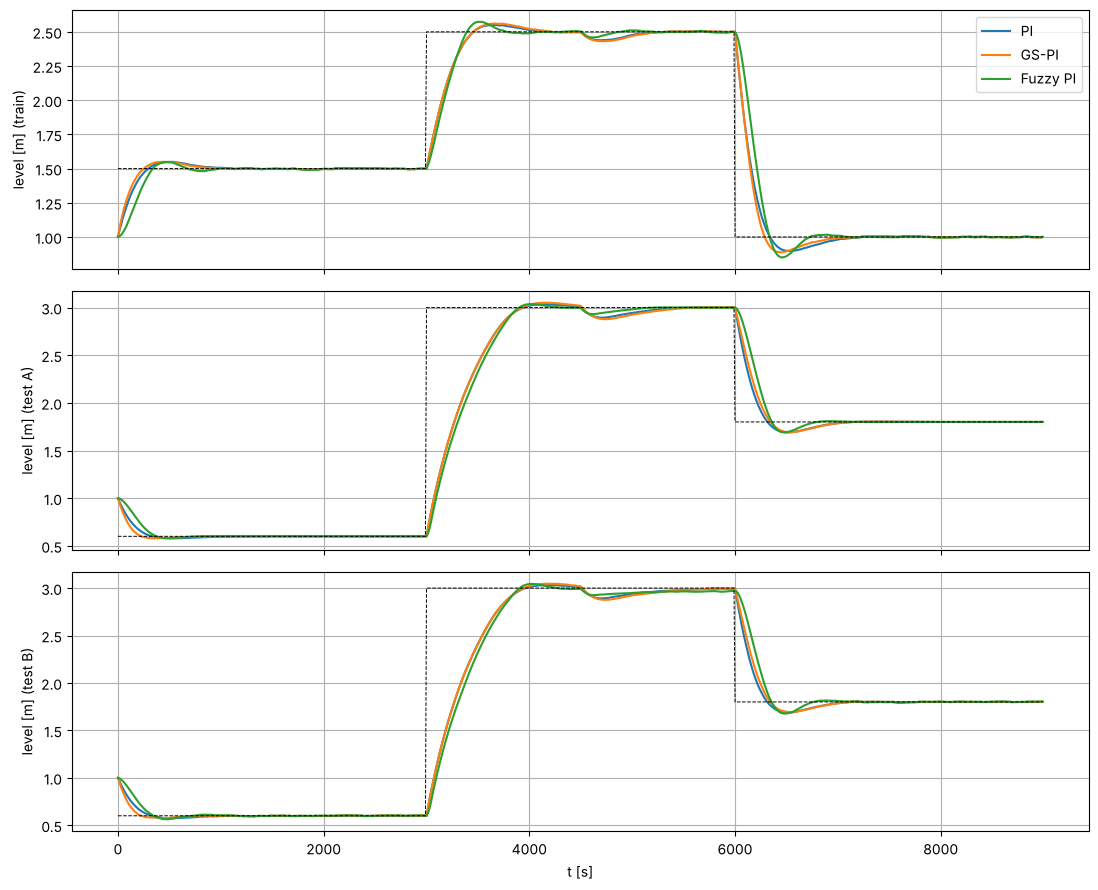

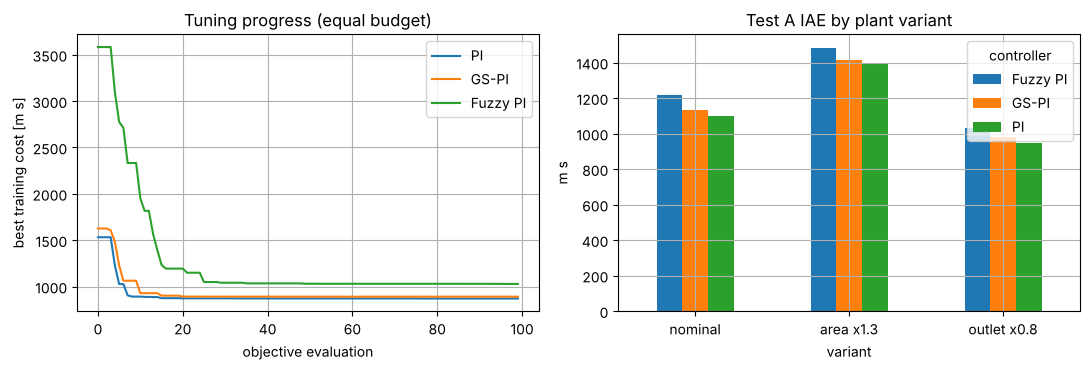

experiments/results/exp_08_fuzzy_pi_tank_level.json


In [6]:
figs = []
fig, ax = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
for a, scen in zip(ax, SCEN):
    for kind in th0:
        o = runs[(scen, kind)]; a.plot(o["t"], o["y"], label=kind)
    a.plot(o["t"], o["r"], "k--", lw=0.7); a.set(ylabel=f"level [m] ({scen})")
ax[0].legend(); ax[-1].set_xlabel("t [s]"); fig.tight_layout()
figs.append(save_figure(fig, EXP, "responses"))
plt.show()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for k, h in hist.items(): ax[0].plot(h, label=k)
ax[0].set(xlabel="objective evaluation", ylabel="best training cost [m s]", title="Tuning progress (equal budget)"); ax[0].legend()
piv = dv.pivot(index="variant", columns="controller", values="iae_total").loc[list(VARS)]
piv.plot.bar(ax=ax[1], rot=0); ax[1].set(title="Test A IAE by plant variant", ylabel="m s")
fig.tight_layout(); figs.append(save_figure(fig, EXP, "tuning_and_variants"))
plt.show()
rec_ = ExperimentRecord(
    experiment_id=EXP, title="Fuzzy PI vs PI vs gain-scheduled PI on a nonlinear tank, matched tuning budget",
    notebook="notebooks/05_intelligent/08_fuzzy.ipynb",
    algorithm="Mamdani fuzzy PI (incremental), PI, gain-scheduled PI; Nelder-Mead tuning",
    application="Tank level control (illustrative)", plant_model="Single tank with sqrt outflow (RK4)",
    dataset={"name": "none", "kind": "simulated", "description": "Simulated tank, illustrative parameters; Gaussian measurement noise in test B."},
    metrics={"table": [{k: v for k, v in r.items()} for r in rows], "plant_variants": vrows, "repeat_tuning": rep, "tuning_evaluations": evals,
             "fuzzy_engine": {"max_nonmonotone_drop": ripple, "phi_1_1_default_grid": c201, "phi_1_1_fine_grid": c_fine, "closed_form": 8 / 9},
             "start": {"kp": kp0, "ti_s": ti0, "ge": ge0, "gde": gde0, "gu": gu0, "slope": s_slope}},
    checks=checks, sampling_time_s=Ts, random_seed=SEED, number_of_trials=len(rows) + len(vrows),
    controller_parameters={k: [float(v) for v in np.exp(tuned[k])] for k in tuned}, plant_parameters={"area_m2": 0.8, "c_out": 0.004, "q_max": QMAX},
    input_configuration={k: v["levels"] for k, v in SCEN.items()}, disturbance_configuration={k: {"outflow_m3s": v["dist"][1], "noise_std_m": v["noise"]} for k, v in SCEN.items()},
    operating_conditions={"tuning_budget_evaluations": 100, "segment_s": SEG}, figure_references=figs,
    limitations=["One plant, one rule base, one tuning algorithm; no statistical repeats over seeds for tuning.",
                 "Illustrative plant parameters; no measured data.",
                 "Local optimiser (Nelder-Mead) from a model-based start; a different start or budget could change the ranking.",
                 "GS-PI uses plant structure the other controllers do not.", "No hardware validation."])
print(rec_.save())